# GPU-Based Connected-Component Labeling — Live CUDA Lab (Google Colab)
**PGD AI (IIT Jodhpur) · GPU Programming · Problem 3**
Ritesh Maury (G25AIT2087) · Shrikrishna Tripathi (G25AIT2103) · Alok Sahni (G25AIT2138)

**Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all** (≈ 6–8 min).
Every cell writes or runs a file from `05_Source_Code/`; nothing else is needed.

## 1 · Check the GPU

In [ ]:
!nvidia-smi
!nvcc --version | tail -1

Sat Oct 17 07:00:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2 · Write the project sources
The cells below write the exact files from the project repository (`src/`, `python/`).

In [ ]:
%%writefile ccl_cuda.cu
/*
 * ccl_cuda.cu  --  GPU-Based Connected-Component Labeling of a Binary Image (CUDA)
 * PGD AI (IIT Jodhpur) · GPU Programming · Problem 3
 * Ritesh Maury (G25AIT2087) · Shrikrishna Tripathi (G25AIT2103) · Alok Sahni (G25AIT2138)
 *
 * Pipeline (all on the device):
 *   init_labels        : label[i] = i for foreground pixels, 0 for background
 *   propagate_labels   : each foreground pixel pulls the minimum label of its
 *                        8 foreground neighbours; sets a device flag if it changed
 *   compress_labels    : pointer-jumping (path compression) to the root label
 *   compact_labels     : root pixels get consecutive ids 1..K via a device counter
 *   component_stats    : area / centroid sums / bounding box with atomics
 *
 * Convergence is detected ON THE GPU: only one int (4 bytes) is copied back per
 * iteration, never the label image.
 *
 * Build : Linux/Colab : nvcc -O3 -arch=sm_75 -o ccl_cuda ccl_cuda.cu
 *         Windows     : nvcc -O3 -arch=sm_86 -o ccl_cuda.exe ccl_cuda.cu   (x64 Native Tools prompt)
 * Usage : ./ccl_cuda --image img.bin [--out-labels lab.bin] [--out-stats stats.csv]
 *                    [--compress-every 4] [--no-compress] [--verbose]
 *         ./ccl_cuda --gen W H [--density 0.5] [--seed 42] [--dump img.bin] ...
 *
 * Binary image format : int32 W, int32 H, then W*H uint8 (0 = background, 1 = foreground), row-major.
 * Labels output       : int32 W, int32 H, then W*H int32 (0 = background, 1..K = component id).
 * Stats output        : CSV  id,area,cx,cy,xmin,ymin,xmax,ymax
 */

#ifdef _MSC_VER
#define _CRT_SECURE_NO_WARNINGS
#endif
#include <cuda_runtime.h>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <cmath>
#include <vector>
#include <string>
#include <random>

#define CUDA_CHECK(call)                                                        \
    do {                                                                        \
        cudaError_t err__ = (call);                                             \
        if (err__ != cudaSuccess) {                                             \
            fprintf(stderr, "CUDA error %s at %s:%d: %s\n", #call, __FILE__,    \
                    __LINE__, cudaGetErrorString(err__));                       \
            exit(EXIT_FAILURE);                                                 \
        }                                                                       \
    } while (0)

static const int BX = 16, BY = 16;      /* 16x16 = 256 threads per block */

/* ------------------------------------------------------------------------ */
/* Kernel 1: initial labels. One thread per pixel.                          */
/* ------------------------------------------------------------------------ */
__global__ void init_labels(const unsigned char* __restrict__ img,
                            int* __restrict__ labels, int W, int H)
{
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= W || y >= H) return;                       /* boundary guard */
    int idx = y * W + x;
    labels[idx] = img[idx] ? idx : 0;                   /* 0 reserved for background */
}

/* ------------------------------------------------------------------------ */
/* Kernel 2: propagation. Pull the minimum label from the 8-neighbourhood.  */
/* Any change sets *d_changed = 1 (device-side convergence flag).           */
/* ------------------------------------------------------------------------ */
__global__ void propagate_labels(const unsigned char* __restrict__ img,
                                 int* __restrict__ labels, int W, int H,
                                 int* __restrict__ d_changed)
{
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= W || y >= H) return;
    int idx = y * W + x;
    if (!img[idx]) return;                              /* background: never labelled */

    int best = labels[idx];
    #pragma unroll
    for (int dy = -1; dy <= 1; ++dy) {
        int ny = y + dy;
        if (ny < 0 || ny >= H) continue;                /* top/bottom edge */
        #pragma unroll
        for (int dx = -1; dx <= 1; ++dx) {
            if (!dx && !dy) continue;
            int nx = x + dx;
            if (nx < 0 || nx >= W) continue;            /* left/right edge */
            int n = ny * W + nx;
            if (!img[n]) continue;                      /* background neighbour */
            int l = labels[n];
            if (l < best) best = l;
        }
    }
    if (best < labels[idx]) {
        labels[idx] = best;
        atomicExch(d_changed, 1);                       /* flag: not yet converged */
    }
}

/* ------------------------------------------------------------------------ */
/* Kernel 3: path compression (pointer jumping). labels[root] == root.      */
/* ------------------------------------------------------------------------ */
__global__ void compress_labels(const unsigned char* __restrict__ img,
                                int* __restrict__ labels, int W, int H)
{
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= W || y >= H) return;
    int idx = y * W + x;
    if (!img[idx]) return;
    int l = labels[idx];
    while (labels[l] != l) l = labels[l];
    labels[idx] = l;
}

/* ------------------------------------------------------------------------ */
/* Kernel 4a: every root pixel (labels[i]==i) claims a consecutive id 1..K  */
/* via one atomicAdd on a device counter -> number of components on GPU.   */
/* ------------------------------------------------------------------------ */
__global__ void assign_ids(const unsigned char* __restrict__ img,
                           const int* __restrict__ labels,
                           int* __restrict__ ids, int N, int* __restrict__ counter)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    if (img[i] && labels[i] == i) ids[i] = 1 + atomicAdd(counter, 1);
}

/* Kernel 4b: every foreground pixel takes the id of its root.              */
__global__ void compact_labels(const unsigned char* __restrict__ img,
                               const int* __restrict__ labels,
                               const int* __restrict__ ids,
                               int* __restrict__ out, int N)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    out[i] = img[i] ? ids[labels[i]] : 0;
}

/* ------------------------------------------------------------------------ */
/* Kernel 5: component statistics. One thread per pixel, atomics per label. */
/* ------------------------------------------------------------------------ */
__global__ void component_stats(const int* __restrict__ lab, int W, int H,
                                int* __restrict__ area,
                                unsigned long long* __restrict__ sumx,
                                unsigned long long* __restrict__ sumy,
                                int* __restrict__ xmin, int* __restrict__ ymin,
                                int* __restrict__ xmax, int* __restrict__ ymax)
{
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= W || y >= H) return;
    int k = lab[y * W + x];
    if (k == 0) return;                                 /* background */
    atomicAdd(&area[k], 1);
    atomicAdd(&sumx[k], (unsigned long long)x);
    atomicAdd(&sumy[k], (unsigned long long)y);
    atomicMin(&xmin[k], x); atomicMin(&ymin[k], y);
    atomicMax(&xmax[k], x); atomicMax(&ymax[k], y);
}

/* ------------------------------------------------------------------------ */
/* Host helpers                                                              */
/* ------------------------------------------------------------------------ */
static bool read_img(const std::string& p, std::vector<unsigned char>& img, int& W, int& H)
{
    FILE* f = fopen(p.c_str(), "rb");
    if (!f) { fprintf(stderr, "cannot open %s\n", p.c_str()); return false; }
    if (fread(&W, 4, 1, f) != 1 || fread(&H, 4, 1, f) != 1) { fclose(f); return false; }
    img.resize((size_t)W * H);
    size_t got = fread(img.data(), 1, img.size(), f);
    fclose(f);
    for (auto& v : img) v = v ? 1 : 0;
    return got == img.size();
}
static void write_img(const std::string& p, const std::vector<unsigned char>& img, int W, int H)
{
    FILE* f = fopen(p.c_str(), "wb"); if (!f) return;
    fwrite(&W, 4, 1, f); fwrite(&H, 4, 1, f); fwrite(img.data(), 1, img.size(), f); fclose(f);
}
static void write_labels(const std::string& p, const std::vector<int>& lab, int W, int H)
{
    FILE* f = fopen(p.c_str(), "wb"); if (!f) return;
    fwrite(&W, 4, 1, f); fwrite(&H, 4, 1, f); fwrite(lab.data(), 4, lab.size(), f); fclose(f);
}

/* synthetic image: random blobs (discs + rectangles) on a background, optional noise */
static void gen_image(int W, int H, float density, unsigned seed, std::vector<unsigned char>& img)
{
    std::mt19937 rng(seed);
    img.assign((size_t)W * H, 0);
    if (density >= 0.99f) { for (auto& v : img) v = 1; return; }
    std::uniform_real_distribution<float> u(0.f, 1.f);
    if (density > 0.f && density < 0.35f) {
        /* blob mode: paint random discs until coverage ~ density */
        long target = (long)(density * W * (long)H), painted = 0;
        std::uniform_int_distribution<int> rx(0, W - 1), ry(0, H - 1);
        int rmax = std::max(3, std::min(W, H) / 40);
        std::uniform_int_distribution<int> rr(2, rmax);
        while (painted < target) {
            int cx = rx(rng), cy = ry(rng), r = rr(rng);
            for (int y = std::max(0, cy - r); y <= std::min(H - 1, cy + r); ++y)
                for (int x = std::max(0, cx - r); x <= std::min(W - 1, cx + r); ++x)
                    if ((x - cx) * (x - cx) + (y - cy) * (y - cy) <= r * r) {
                        unsigned char& v = img[(size_t)y * W + x];
                        if (!v) { v = 1; ++painted; }
                    }
        }
    } else {
        /* noise mode: each pixel foreground with probability = density */
        for (auto& v : img) v = (u(rng) < density) ? 1 : 0;
    }
}

int main(int argc, char** argv)
{
    std::string img_path, out_labels = "labels.bin", out_stats = "stats.csv", dump_path;
    int W = 0, H = 0, compress_every = 4, max_iters = 100000;
    float density = 0.3f; unsigned seed = 42;
    bool gen = false, verbose = false, compress = true;

    for (int a = 1; a < argc; ++a) {
        std::string s = argv[a];
        auto next = [&](const char* what) -> const char* {
            if (a + 1 >= argc) { fprintf(stderr, "missing value for %s\n", what); exit(1); }
            return argv[++a];
        };
        if      (s == "--image")          img_path   = next("--image");
        else if (s == "--out-labels")     out_labels = next("--out-labels");
        else if (s == "--out-stats")      out_stats  = next("--out-stats");
        else if (s == "--dump")           dump_path  = next("--dump");
        else if (s == "--compress-every") compress_every = atoi(next("--compress-every"));
        else if (s == "--no-compress")    compress = false;
        else if (s == "--max-iters")      max_iters = atoi(next("--max-iters"));
        else if (s == "--density")        density = (float)atof(next("--density"));
        else if (s == "--seed")           seed = (unsigned)atoi(next("--seed"));
        else if (s == "--verbose")        verbose = true;
        else if (s == "--gen") { gen = true; W = atoi(next("--gen W")); H = atoi(next("H")); }
        else { fprintf(stderr, "unknown arg %s\n", s.c_str()); return 1; }
    }

    std::vector<unsigned char> h_img;
    if (gen) { gen_image(W, H, density, seed, h_img); if (!dump_path.empty()) write_img(dump_path, h_img, W, H); }
    else if (!read_img(img_path, h_img, W, H)) return 1;
    const int N = W * H;

    int dev = 0; cudaDeviceProp prop; CUDA_CHECK(cudaGetDeviceProperties(&prop, dev));
    dim3 block(BX, BY), grid((W + BX - 1) / BX, (H + BY - 1) / BY);
    int grid1d = (N + 255) / 256;

    unsigned char* d_img; int *d_lab, *d_ids, *d_out, *d_changed, *d_count;
    CUDA_CHECK(cudaMalloc(&d_img, N));
    CUDA_CHECK(cudaMalloc(&d_lab, (size_t)N * 4));
    CUDA_CHECK(cudaMalloc(&d_ids, (size_t)N * 4));
    CUDA_CHECK(cudaMalloc(&d_out, (size_t)N * 4));
    CUDA_CHECK(cudaMalloc(&d_changed, 4));
    CUDA_CHECK(cudaMalloc(&d_count, 4));
    CUDA_CHECK(cudaMemcpy(d_img, h_img.data(), N, cudaMemcpyHostToDevice));

    cudaEvent_t e0, e1, eA, eB;
    CUDA_CHECK(cudaEventCreate(&e0)); CUDA_CHECK(cudaEventCreate(&e1));
    CUDA_CHECK(cudaEventCreate(&eA)); CUDA_CHECK(cudaEventCreate(&eB));
    float t, label_ms = 0.f, stats_ms = 0.f;

    if (verbose)
        fprintf(stderr, "[host] gpu=%s SMs=%d | W=%d H=%d N=%d | block=%dx%d grid=%dx%d | compress_every=%d\n",
                prop.name, prop.multiProcessorCount, W, H, N, BX, BY, grid.x, grid.y, compress ? compress_every : 0);

    CUDA_CHECK(cudaEventRecord(e0));
    /* ---- labelling loop ------------------------------------------------ */
    init_labels<<<grid, block>>>(d_img, d_lab, W, H);
    int iters = 0, changed = 1;
    while (changed && iters < max_iters) {
        CUDA_CHECK(cudaMemsetAsync(d_changed, 0, 4));
        CUDA_CHECK(cudaEventRecord(eA));
        propagate_labels<<<grid, block>>>(d_img, d_lab, W, H, d_changed);
        if (compress && ((iters + 1) % compress_every == 0))
            compress_labels<<<grid, block>>>(d_img, d_lab, W, H);
        CUDA_CHECK(cudaEventRecord(eB));
        /* ONLY 4 bytes cross the PCIe bus per iteration */
        CUDA_CHECK(cudaMemcpy(&changed, d_changed, 4, cudaMemcpyDeviceToHost));
        CUDA_CHECK(cudaEventElapsedTime(&t, eA, eB)); label_ms += t;
        ++iters;
        if (verbose) fprintf(stderr, "[iter %3d] propagate%s %.3f ms  changed=%d%s\n", iters,
                             (compress && iters % compress_every == 0) ? "+compress" : "         ", t, changed,
                             changed ? "" : "  => CONVERGED");
    }
    compress_labels<<<grid, block>>>(d_img, d_lab, W, H);       /* final flatten */
    CUDA_CHECK(cudaGetLastError());

    /* ---- compaction to 1..K (K counted on the device) ------------------ */
    CUDA_CHECK(cudaMemset(d_count, 0, 4));
    assign_ids<<<grid1d, 256>>>(d_img, d_lab, d_ids, N, d_count);
    compact_labels<<<grid1d, 256>>>(d_img, d_lab, d_ids, d_out, N);
    int K = 0; CUDA_CHECK(cudaMemcpy(&K, d_count, 4, cudaMemcpyDeviceToHost));

    /* ---- component statistics ----------------------------------------- */
    int *d_area, *d_xmin, *d_ymin, *d_xmax, *d_ymax; unsigned long long *d_sx, *d_sy;
    size_t kb = (size_t)(K + 1) * 4;
    CUDA_CHECK(cudaMalloc(&d_area, kb)); CUDA_CHECK(cudaMalloc(&d_xmin, kb)); CUDA_CHECK(cudaMalloc(&d_ymin, kb));
    CUDA_CHECK(cudaMalloc(&d_xmax, kb)); CUDA_CHECK(cudaMalloc(&d_ymax, kb));
    CUDA_CHECK(cudaMalloc(&d_sx, (K + 1) * 8ull)); CUDA_CHECK(cudaMalloc(&d_sy, (K + 1) * 8ull));
    CUDA_CHECK(cudaMemset(d_area, 0, kb)); CUDA_CHECK(cudaMemset(d_sx, 0, (K + 1) * 8ull)); CUDA_CHECK(cudaMemset(d_sy, 0, (K + 1) * 8ull));
    CUDA_CHECK(cudaMemset(d_xmin, 0x7F, kb)); CUDA_CHECK(cudaMemset(d_ymin, 0x7F, kb));   /* INT_MAX-ish */
    CUDA_CHECK(cudaMemset(d_xmax, 0xFF, kb)); CUDA_CHECK(cudaMemset(d_ymax, 0xFF, kb));   /* -1 */
    CUDA_CHECK(cudaEventRecord(eA));
    component_stats<<<grid, block>>>(d_out, W, H, d_area, d_sx, d_sy, d_xmin, d_ymin, d_xmax, d_ymax);
    CUDA_CHECK(cudaEventRecord(eB)); CUDA_CHECK(cudaEventSynchronize(eB));
    CUDA_CHECK(cudaEventElapsedTime(&stats_ms, eA, eB));
    CUDA_CHECK(cudaEventRecord(e1)); CUDA_CHECK(cudaEventSynchronize(e1));
    float total_ms; CUDA_CHECK(cudaEventElapsedTime(&total_ms, e0, e1));

    /* ---- copy results back once --------------------------------------- */
    std::vector<int> h_lab(N), area(K + 1), xmin(K + 1), ymin(K + 1), xmax(K + 1), ymax(K + 1);
    std::vector<unsigned long long> sx(K + 1), sy(K + 1);
    CUDA_CHECK(cudaMemcpy(h_lab.data(), d_out, (size_t)N * 4, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(area.data(), d_area, kb, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(sx.data(), d_sx, (K + 1) * 8ull, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(sy.data(), d_sy, (K + 1) * 8ull, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(xmin.data(), d_xmin, kb, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(ymin.data(), d_ymin, kb, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(xmax.data(), d_xmax, kb, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(ymax.data(), d_ymax, kb, cudaMemcpyDeviceToHost));

    write_labels(out_labels, h_lab, W, H);
    FILE* fs = fopen(out_stats.c_str(), "w");
    if (fs) {
        fprintf(fs, "id,area,cx,cy,xmin,ymin,xmax,ymax\n");
        for (int k = 1; k <= K; ++k)
            fprintf(fs, "%d,%d,%.4f,%.4f,%d,%d,%d,%d\n", k, area[k],
                    (double)sx[k] / area[k], (double)sy[k] / area[k], xmin[k], ymin[k], xmax[k], ymax[k]);
        fclose(fs);
    }
    long fg = 0; for (auto v : h_img) fg += v;
    printf("RESULT W=%d H=%d N=%d fg=%ld components=%d iters=%d time_ms=%.3f label_ms=%.3f stats_ms=%.3f "
           "compress_every=%d gpu=\"%s\"\n", W, H, N, fg, K, iters, total_ms, label_ms, stats_ms,
           compress ? compress_every : 0, prop.name);

    cudaFree(d_img); cudaFree(d_lab); cudaFree(d_ids); cudaFree(d_out); cudaFree(d_changed); cudaFree(d_count);
    cudaFree(d_area); cudaFree(d_sx); cudaFree(d_sy); cudaFree(d_xmin); cudaFree(d_ymin); cudaFree(d_xmax); cudaFree(d_ymax);
    return 0;
}


Overwriting ccl_cuda.cu


In [ ]:
%%writefile ccl_cpu.c
/* ccl_cpu.c -- sequential reference for Connected-Component Labeling (8-connectivity).
 * Two modes:
 *   --algo bfs   : flood-fill with an explicit queue (fast, used for verification and CPU baseline)
 *   --algo prop  : the SAME iterative min-label propagation the GPU runs, executed serially
 *                  (reports iteration count; shows why the GPU version needs parallelism)
 * Build: gcc -O3 -o ccl_cpu ccl_cpu.c            (MSVC: cl /O2 ccl_cpu.c)
 * Usage: ./ccl_cpu --image img.bin [--algo bfs|prop] [--out-labels l.bin] [--out-stats s.csv]
 * Same file formats as ccl_cuda.cu; labels are 1..K in first-encounter (raster) order.       */
#ifdef _MSC_VER
#define _CRT_SECURE_NO_WARNINGS
#endif
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <time.h>
#ifdef _WIN32
  #define WIN32_LEAN_AND_MEAN
  #include <windows.h>
  static double now_ms(void){ LARGE_INTEGER f,c; QueryPerformanceFrequency(&f); QueryPerformanceCounter(&c); return 1e3*(double)c.QuadPart/(double)f.QuadPart; }
#else
  static double now_ms(void){ struct timespec t; clock_gettime(CLOCK_MONOTONIC,&t); return t.tv_sec*1e3+t.tv_nsec/1e6; }
#endif

int main(int argc, char** argv){
    const char *img=NULL,*ol="labels_cpu.bin",*os="stats_cpu.csv",*algo="bfs";
    for(int a=1;a<argc;a++){
        if(!strcmp(argv[a],"--image")) img=argv[++a];
        else if(!strcmp(argv[a],"--algo")) algo=argv[++a];
        else if(!strcmp(argv[a],"--out-labels")) ol=argv[++a];
        else if(!strcmp(argv[a],"--out-stats")) os=argv[++a];
    }
    if(!img){fprintf(stderr,"usage: --image img.bin [--algo bfs|prop]\n");return 1;}
    FILE* f=fopen(img,"rb"); if(!f){perror("image");return 1;}
    int W,H; if(fread(&W,4,1,f)!=1||fread(&H,4,1,f)!=1) return 1;
    long N=(long)W*H; unsigned char* I=malloc(N); if(fread(I,1,N,f)!=(size_t)N) return 1; fclose(f);
    int* L=calloc(N,sizeof(int)); int K=0, iters=0;
    double t0=now_ms();

    if(!strcmp(algo,"bfs")){
        long* q=malloc(N*sizeof(long));
        for(long s=0;s<N;s++){
            if(!I[s]||L[s]) continue;
            K++; long qh=0,qt=0; q[qt++]=s; L[s]=K;
            while(qh<qt){
                long p=q[qh++]; int x=(int)(p%W), y=(int)(p/W);
                for(int dy=-1;dy<=1;dy++){ int ny=y+dy; if(ny<0||ny>=H) continue;
                    for(int dx=-1;dx<=1;dx++){ int nx=x+dx; if(nx<0||nx>=W||(!dx&&!dy)) continue;
                        long n=(long)ny*W+nx; if(I[n]&&!L[n]){L[n]=K;q[qt++]=n;} } }
            }
        }
        free(q);
    } else { /* serial version of the GPU min-label propagation, for iteration counts */
        for(long i=0;i<N;i++) L[i]=I[i]?(int)i:0;
        int changed=1;
        while(changed){ changed=0; iters++;
            for(long p=0;p<N;p++){ if(!I[p]) continue; int x=(int)(p%W), y=(int)(p/W); int best=L[p];
                for(int dy=-1;dy<=1;dy++){ int ny=y+dy; if(ny<0||ny>=H) continue;
                    for(int dx=-1;dx<=1;dx++){ int nx=x+dx; if(nx<0||nx>=W||(!dx&&!dy)) continue;
                        long n=(long)ny*W+nx; if(I[n]&&L[n]<best) best=L[n]; } }
                if(best<L[p]){L[p]=best;changed=1;} }
            if(iters%4==0) for(long p=0;p<N;p++){ if(!I[p]) continue; int l=L[p]; while(L[l]!=l) l=L[l]; L[p]=l; }
        }
        for(long p=0;p<N;p++){ if(!I[p]) continue; int l=L[p]; while(L[l]!=l) l=L[l]; L[p]=l; }
        int* id=calloc(N,sizeof(int));
        for(long p=0;p<N;p++) if(I[p]){ int r=L[p]; if(!id[r]) id[r]=++K; }
        for(long p=0;p<N;p++) L[p]=I[p]?id[L[p]]:0;
        free(id);
    }
    double ms=now_ms()-t0;

    /* statistics */
    long *area=calloc(K+1,8),*sx=calloc(K+1,8),*sy=calloc(K+1,8);
    int *x0=malloc((K+1)*4),*y0=malloc((K+1)*4),*x1=malloc((K+1)*4),*y1=malloc((K+1)*4);
    for(int k=0;k<=K;k++){x0[k]=W;y0[k]=H;x1[k]=-1;y1[k]=-1;}
    for(long p=0;p<N;p++){ int k=L[p]; if(!k) continue; int x=(int)(p%W),y=(int)(p/W);
        area[k]++; sx[k]+=x; sy[k]+=y; if(x<x0[k])x0[k]=x; if(y<y0[k])y0[k]=y; if(x>x1[k])x1[k]=x; if(y>y1[k])y1[k]=y; }
    double ms_total=now_ms()-t0;

    f=fopen(ol,"wb"); fwrite(&W,4,1,f); fwrite(&H,4,1,f); fwrite(L,4,N,f); fclose(f);
    f=fopen(os,"w"); fprintf(f,"id,area,cx,cy,xmin,ymin,xmax,ymax\n");
    for(int k=1;k<=K;k++) fprintf(f,"%d,%ld,%.4f,%.4f,%d,%d,%d,%d\n",k,area[k],(double)sx[k]/area[k],(double)sy[k]/area[k],x0[k],y0[k],x1[k],y1[k]);
    fclose(f);
    long fg=0; for(long i=0;i<N;i++) fg+=I[i]?1:0;
    printf("RESULT mode=cpu-%s W=%d H=%d N=%ld fg=%ld components=%d iters=%d time_ms=%.3f label_ms=%.3f stats_ms=%.3f\n",
           algo,W,H,N,fg,K,iters,ms_total,ms,ms_total-ms);
    return 0;
}


Overwriting ccl_cpu.c


In [ ]:
%%writefile ccl_io.py
"""Binary I/O shared by all Python tools.
Image : int32 W, int32 H, uint8[W*H]   (0 = background, 1 = foreground)
Labels: int32 W, int32 H, int32[W*H]   (0 = background, 1..K = component id)
"""
import numpy as np

def write_image(path, img):
    img = np.asarray(img, dtype=np.uint8); H, W = img.shape
    with open(path, 'wb') as f:
        np.array([W, H], dtype=np.int32).tofile(f); (img != 0).astype(np.uint8).tofile(f)

def read_image(path):
    with open(path, 'rb') as f:
        W, H = np.fromfile(f, dtype=np.int32, count=2); return np.fromfile(f, dtype=np.uint8, count=W*H).reshape(H, W)

def read_labels(path):
    with open(path, 'rb') as f:
        W, H = np.fromfile(f, dtype=np.int32, count=2); return np.fromfile(f, dtype=np.int32, count=W*H).reshape(H, W)

def read_stats(path):
    import csv
    with open(path) as f:
        rows = list(csv.DictReader(f))
    return {int(r['id']): dict(area=int(r['area']), cx=float(r['cx']), cy=float(r['cy']),
            xmin=int(r['xmin']), ymin=int(r['ymin']), xmax=int(r['xmax']), ymax=int(r['ymax'])) for r in rows}


Overwriting ccl_io.py


In [ ]:
%%writefile gen_image.py
"""Generate synthetic binary test images.
Usage: python gen_image.py out.bin W H [--kind blobs|noise|shapes] [--density 0.3] [--seed 42] [--png out.png]
  blobs  : random discs (default) — realistic object-like components
  noise  : i.i.d. pixels with P(fg)=density — worst case, many tiny components
  shapes : rectangles, ring, diagonal lines, one long snake — stresses path compression
"""
import argparse, numpy as np
from ccl_io import write_image

def blobs(W, H, density, rng):
    img = np.zeros((H, W), np.uint8); target = density * W * H; yy, xx = np.mgrid[0:H, 0:W]
    rmax = max(3, min(W, H) // 40)
    while img.sum() < target:
        cx, cy, r = rng.integers(W), rng.integers(H), rng.integers(2, rmax + 1)
        y0, y1, x0, x1 = max(0, cy-r), min(H, cy+r+1), max(0, cx-r), min(W, cx+r+1)
        sub = (xx[y0:y1, x0:x1]-cx)**2 + (yy[y0:y1, x0:x1]-cy)**2 <= r*r
        img[y0:y1, x0:x1] |= sub.astype(np.uint8)
    return img

def noise(W, H, density, rng): return (rng.random((H, W)) < density).astype(np.uint8)

def shapes(W, H, density, rng):
    img = np.zeros((H, W), np.uint8)
    for _ in range(max(1, W*H // 20000)):                     # rectangles
        x, y = rng.integers(W-20), rng.integers(H-20); w, h = rng.integers(5, 20), rng.integers(5, 20)
        img[y:y+h, x:x+w] = 1
    for _ in range(max(1, W // 64)):                          # diagonal lines (8-connectivity!)
        x, y = rng.integers(W//2), rng.integers(H//2); n = rng.integers(10, min(W, H)//2)
        for i in range(n):
            if y+i < H and x+i < W: img[y+i, x+i] = 1
    yy, xx = np.mgrid[0:H, 0:W]; cx, cy, r = W//4, H//4, min(W, H)//8  # ring
    d = (xx-cx)**2 + (yy-cy)**2; img[(d <= r*r) & (d >= (r-3)**2)] = 1
    x, y = W//2, 2                                            # one long snake -> many iterations without compression
    while y < H-2 and 2 < x < W-2:
        img[y, x] = 1; x += int(rng.integers(3)) - 1; y += 1 if rng.random() < 0.5 else 0
    return img

if __name__ == '__main__':
    ap = argparse.ArgumentParser(); ap.add_argument('out'); ap.add_argument('W', type=int); ap.add_argument('H', type=int)
    ap.add_argument('--kind', default='blobs', choices=['blobs', 'noise', 'shapes']); ap.add_argument('--density', type=float, default=0.3)
    ap.add_argument('--seed', type=int, default=42); ap.add_argument('--png')
    a = ap.parse_args(); rng = np.random.default_rng(a.seed)
    img = {'blobs': blobs, 'noise': noise, 'shapes': shapes}[a.kind](a.W, a.H, a.density, rng)
    write_image(a.out, img); print(f'wrote {a.out}: {a.W}x{a.H}, foreground={int(img.sum())} ({100*img.mean():.1f}%)')
    if a.png:
        import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
        plt.imsave(a.png, img, cmap='gray')


Overwriting gen_image.py


In [ ]:
%%writefile ccl_numpy.py
"""Pure-NumPy/SciPy reference: labels + statistics for a binary image (8-connectivity).
Uses scipy.ndimage.label if available; otherwise a BFS fallback. Same semantics as ccl_cpu.c."""
import numpy as np

def label_numpy(img):
    img = (np.asarray(img) != 0)
    try:
        from scipy import ndimage
        lab, K = ndimage.label(img, structure=np.ones((3, 3), int)); return lab.astype(np.int32), int(K)
    except ImportError:
        H, W = img.shape; lab = np.zeros((H, W), np.int32); K = 0
        for sy in range(H):
            for sx in range(W):
                if not img[sy, sx] or lab[sy, sx]: continue
                K += 1; st = [(sy, sx)]; lab[sy, sx] = K
                while st:
                    y, x = st.pop()
                    for dy in (-1, 0, 1):
                        for dx in (-1, 0, 1):
                            ny, nx = y+dy, x+dx
                            if 0 <= ny < H and 0 <= nx < W and img[ny, nx] and not lab[ny, nx]:
                                lab[ny, nx] = K; st.append((ny, nx))
        return lab, K

def stats_numpy(lab):
    K = int(lab.max()); H, W = lab.shape; yy, xx = np.mgrid[0:H, 0:W]; flat = lab.ravel()
    area = np.bincount(flat, minlength=K+1); sx = np.bincount(flat, weights=xx.ravel(), minlength=K+1); sy = np.bincount(flat, weights=yy.ravel(), minlength=K+1)
    order = np.argsort(flat, kind='stable'); bounds = np.searchsorted(flat[order], np.arange(K+2)); out = {}
    for k in range(1, K+1):
        idx = order[bounds[k]:bounds[k+1]]; xs, ys = idx % W, idx // W
        out[k] = dict(area=int(area[k]), cx=sx[k]/area[k], cy=sy[k]/area[k], xmin=int(xs.min()), ymin=int(ys.min()), xmax=int(xs.max()), ymax=int(ys.max()))
    return out


Overwriting ccl_numpy.py


In [ ]:
%%writefile verify.py
"""Verify a labelled image against the reference.
Usage: python verify.py image.bin labels_test.bin [stats_test.csv] [--ref-labels labels_ref.bin]
Component ids may differ between implementations, so we check that the PARTITION is identical
(one-to-one mapping test<->ref) and that per-component area / centroid / bbox agree."""
import sys, numpy as np
from ccl_io import read_image, read_labels, read_stats
from ccl_numpy import label_numpy, stats_numpy

def partition_equal(a, b):
    if a.shape != b.shape or not np.array_equal(a == 0, b == 0): return False
    fg = a != 0; pa, pb = a[fg].astype(np.int64), b[fg].astype(np.int64)
    pairs = np.unique(pa * (pb.max() + 1) + pb)
    return len(pairs) == len(np.unique(pa)) == len(np.unique(pb))

if __name__ == '__main__':
    args = [x for x in sys.argv[1:] if not x.startswith('--') and x != sys.argv[sys.argv.index('--ref-labels')+1] if '--ref-labels' in sys.argv] if '--ref-labels' in sys.argv else [x for x in sys.argv[1:] if not x.startswith('--')]
    img = read_image(args[0]); test = read_labels(args[1])
    if '--ref-labels' in sys.argv: ref = read_labels(sys.argv[sys.argv.index('--ref-labels') + 1]); K = int(ref.max())
    else: ref, K = label_numpy(img)
    ok = partition_equal(test, ref); print(f'components: test={int(test.max())} ref={K}  partition identical: {ok}')
    if len(args) > 2:
        st = read_stats(args[2]); rs = stats_numpy(ref); bad = 0
        first = {}
        for i, k in enumerate(test.ravel()):
            if k and k not in first: first[k] = i
            if len(first) == len(st): break
        for k in st:
            i = first[k]; r = int(ref.ravel()[i]); q = rs[r]
            if (st[k]['area'] != q['area'] or abs(st[k]['cx']-q['cx']) > 1e-3 or abs(st[k]['cy']-q['cy']) > 1e-3 or
                (st[k]['xmin'], st[k]['ymin'], st[k]['xmax'], st[k]['ymax']) != (q['xmin'], q['ymin'], q['xmax'], q['ymax'])): bad += 1
        print(f'statistics: {len(st)} components checked, {bad} mismatches'); ok = ok and bad == 0
    print('PASS' if ok else 'FAIL'); sys.exit(0 if ok else 1)


Overwriting verify.py


In [ ]:
%%writefile benchmark.py
"""Benchmark sweep: GPU (with / without path compression) vs CPU BFS baseline.
Usage: python benchmark.py --exe ./ccl_cuda --cpu ./ccl_cpu --out benchmark.csv
                           [--sizes 256,512,1024,2048,4096] [--kinds blobs,noise,shapes] [--reps 3]"""
import argparse, subprocess, re, csv, os, sys, tempfile
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from gen_image import blobs, noise, shapes; from ccl_io import write_image; import numpy as np

def run(cmd):
    out = subprocess.run(cmd, capture_output=True, text=True).stdout
    m = re.search(r'RESULT (.*)', out)
    if not m:
        return None
    # Use a regex that handles both unquoted key=value and key="value with spaces"
    kv_pairs = re.findall(r'(\w+)=(?:"([^"]*)"|(\S+))', m.group(1))
    return {k: (v1 if v1 != '' else v2) for k, v1, v2 in kv_pairs}

if __name__ == '__main__':
    ap = argparse.ArgumentParser(); ap.add_argument('--exe', default='./ccl_cuda'); ap.add_argument('--cpu', default='./ccl_cpu')
    ap.add_argument('--out', default='benchmark.csv'); ap.add_argument('--sizes', default='256,512,1024,2048,4096')
    ap.add_argument('--kinds', default='blobs,noise,shapes'); ap.add_argument('--reps', type=int, default=3); ap.add_argument('--gpu-only', action='store_true')
    a = ap.parse_args(); rows = []; tmp = tempfile.mkdtemp()
    for kind in a.kinds.split(','):
        for s in map(int, a.sizes.split(',')):
            rng = np.random.default_rng(42); img = {'blobs': blobs, 'noise': noise, 'shapes': shapes}[kind](s, s, 0.5 if kind == 'noise' else 0.3, rng)
            p = os.path.join(tmp, f'{kind}_{s}.bin'); write_image(p, img)
            modes = [('gpu-compress', []), ('gpu-nocompress', ['--no-compress'])] if os.path.exists(a.exe) else []
            for mode, extra in modes:
                for r in range(a.reps):
                    d = run([a.exe, '--image', p, '--out-labels', os.devnull, '--out-stats', os.devnull] + extra)
                    if d: d.update(kind=kind, size=s, mode=mode, rep=r); rows.append(d); print(kind, s, mode, r, d['time_ms'], 'ms', d['iters'], 'iters', flush=True)
            if not a.gpu_only and os.path.exists(a.cpu):
                for algo in ('bfs', 'prop'):
                    if algo == 'prop' and s > 1024: continue          # serial propagation is very slow on big images
                    d = run([a.cpu, '--image', p, '--algo', algo, '--out-labels', os.devnull, '--out-stats', os.devnull])
                    if d: d.update(kind=kind, size=s, mode='cpu-' + algo, rep=0); rows.append(d); print(kind, s, 'cpu-' + algo, d['time_ms'], 'ms', flush=True)
    keys = sorted({k for r in rows for k in r})
    with open(a.out, 'w', newline='') as f: w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(rows)
    print('wrote', a.out)

Overwriting benchmark.py


In [ ]:
%%writefile plot_results.py
"""Plot benchmark.csv -> 3-panel figure: time vs size, speed-up vs size, iterations (compress vs none).
Usage: python plot_results.py benchmark.csv fig_gpu_benchmark.png"""
import sys, pandas as pd, matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
df = pd.read_csv(sys.argv[1]); df['time_ms'] = df['time_ms'].astype(float); df['iters'] = df['iters'].astype(int)
g = df.groupby(['kind', 'size', 'mode']).agg(time_ms=('time_ms', 'min'), iters=('iters', 'max')).reset_index()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4)); kinds = sorted(g['kind'].unique()); col = dict(zip(kinds, ['C0', 'C1', 'C2']))
for kind in kinds:
    s = g[g['kind'] == kind]
    for mode, st in [('cpu-bfs', '--'), ('gpu-compress', '-'), ('gpu-nocompress', ':')]:
        q = s[s['mode'] == mode].sort_values('size')
        if len(q): ax[0].plot(q['size'], q['time_ms'], st, color=col[kind], marker='o', label=f'{kind} · {mode}')
    c = s[s['mode'] == 'cpu-bfs'].set_index('size')['time_ms']; gpu = s[s['mode'] == 'gpu-compress'].set_index('size')['time_ms']
    common = c.index.intersection(gpu.index)
    if len(common): ax[1].plot(common, c[common] / gpu[common], color=col[kind], marker='o', label=kind)
    for mode, st in [('gpu-compress', '-'), ('gpu-nocompress', ':'), ('cpu-prop', '-.')]:
        q = s[s['mode'] == mode].sort_values('size')
        if len(q) and q['iters'].max() > 0: ax[2].plot(q['size'], q['iters'], st, color=col[kind], marker='s', label=f'{kind} · {mode}')
ax[0].set(xscale='log', yscale='log', xlabel='image side (px)', ylabel='time (ms)', title='Total time: CPU BFS vs GPU'); ax[0].legend(fontsize=7)
ax[1].set(xscale='log', xlabel='image side (px)', ylabel='speed-up ×', title='GPU speed-up over CPU BFS'); ax[1].legend(fontsize=8); ax[1].axhline(1, color='k', lw=.5)
ax[2].set(xscale='log', yscale='log', xlabel='image side (px)', ylabel='iterations', title='Propagation iterations: compress vs none'); ax[2].legend(fontsize=7)
for a in ax: a.grid(alpha=.3, which='both')
plt.tight_layout(); plt.savefig(sys.argv[2], dpi=150); print('wrote', sys.argv[2])


Overwriting plot_results.py


In [ ]:
%%writefile visualize.py
"""Render image + coloured labels + centroids/bounding boxes.
Usage: python visualize.py image.bin labels.bin stats.csv out.png [--max-boxes 60]"""
import sys, numpy as np, matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt; from matplotlib.patches import Rectangle
from ccl_io import read_image, read_labels, read_stats
img, lab, st = read_image(sys.argv[1]), read_labels(sys.argv[2]), read_stats(sys.argv[3]); maxb = 60
if '--max-boxes' in sys.argv: maxb = int(sys.argv[sys.argv.index('--max-boxes')+1])
K = int(lab.max()); rng = np.random.default_rng(0); pal = np.vstack([[0.06, 0.06, 0.1], rng.uniform(.3, 1, (K, 3))])
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))
ax[0].imshow(img, cmap='gray'); ax[0].set_title(f'binary image {img.shape[1]}×{img.shape[0]}  ({100*img.mean():.0f}% foreground)')
ax[1].imshow(pal[lab]); ax[1].set_title(f'{K} connected components (8-connectivity)')
ax[2].imshow(pal[lab]); ax[2].set_title('centroid (+) and bounding box' + (f' — largest {maxb}' if K > maxb else ''))
for k, s in sorted(st.items(), key=lambda kv: -kv[1]['area'])[:maxb]:
    ax[2].add_patch(Rectangle((s['xmin']-.5, s['ymin']-.5), s['xmax']-s['xmin']+1, s['ymax']-s['ymin']+1, fill=False, ec='yellow', lw=.9))
    ax[2].plot(s['cx'], s['cy'], '+', color='cyan', ms=7, mew=1.3)
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(sys.argv[4], dpi=150); print('wrote', sys.argv[4])


Overwriting visualize.py


In [ ]:
%%writefile parse_colab_output.py
"""Summarise benchmark.csv into the table used in the report.
Usage: python parse_colab_output.py benchmark.csv benchmark_summary.csv"""
import sys, pandas as pd
df = pd.read_csv(sys.argv[1]); df['time_ms'] = df.time_ms.astype(float); df['iters'] = df.iters.astype(int)
g = df.groupby(['kind', 'size', 'mode']).agg(time_ms=('time_ms', 'min'), iters=('iters', 'max'), components=('components', 'first')).reset_index()
p = g.pivot_table(index=['kind', 'size'], columns='mode', values='time_ms').reset_index()
it = g.pivot_table(index=['kind', 'size'], columns='mode', values='iters').reset_index()
for m in ('gpu-compress', 'gpu-nocompress', 'cpu-prop'):
    if m in it: p['iters_' + m] = it[m].values
p['components'] = g[g['mode'] == g['mode'].iloc[0]].set_index(['kind', 'size'])['components'].reindex(list(zip(p['kind'], p['size']))).values
if 'cpu-bfs' in p and 'gpu-compress' in p: p['speedup_cpu/gpu'] = (p['cpu-bfs'] / p['gpu-compress']).round(1)
p.to_csv(sys.argv[2], index=False); print(p.to_string(index=False))


Overwriting parse_colab_output.py


## 3 · Compile
`-arch=sm_75` targets the Tesla T4; the cell auto-detects the compute capability if Colab gives you a different GPU.

In [ ]:
import subprocess
cc = subprocess.run(['nvidia-smi','--query-gpu=compute_cap','--format=csv,noheader'],capture_output=True,text=True).stdout.strip().split('\n')[0]
arch = 'sm_' + cc.replace('.','')
print('compute capability', cc, '->', arch)
!nvcc -O3 -arch={arch} -o ccl_cuda ccl_cuda.cu && echo CUDA_BUILD_OK
!gcc -O3 -o ccl_cpu ccl_cpu.c && echo CPU_BUILD_OK

compute capability 7.5 -> sm_75
CUDA_BUILD_OK
CPU_BUILD_OK


## 4 · Generate a test image (1024 × 1024, random blobs, 30 % foreground)

wrote blobs.bin: 1024x1024, foreground=316435 (30.2%)


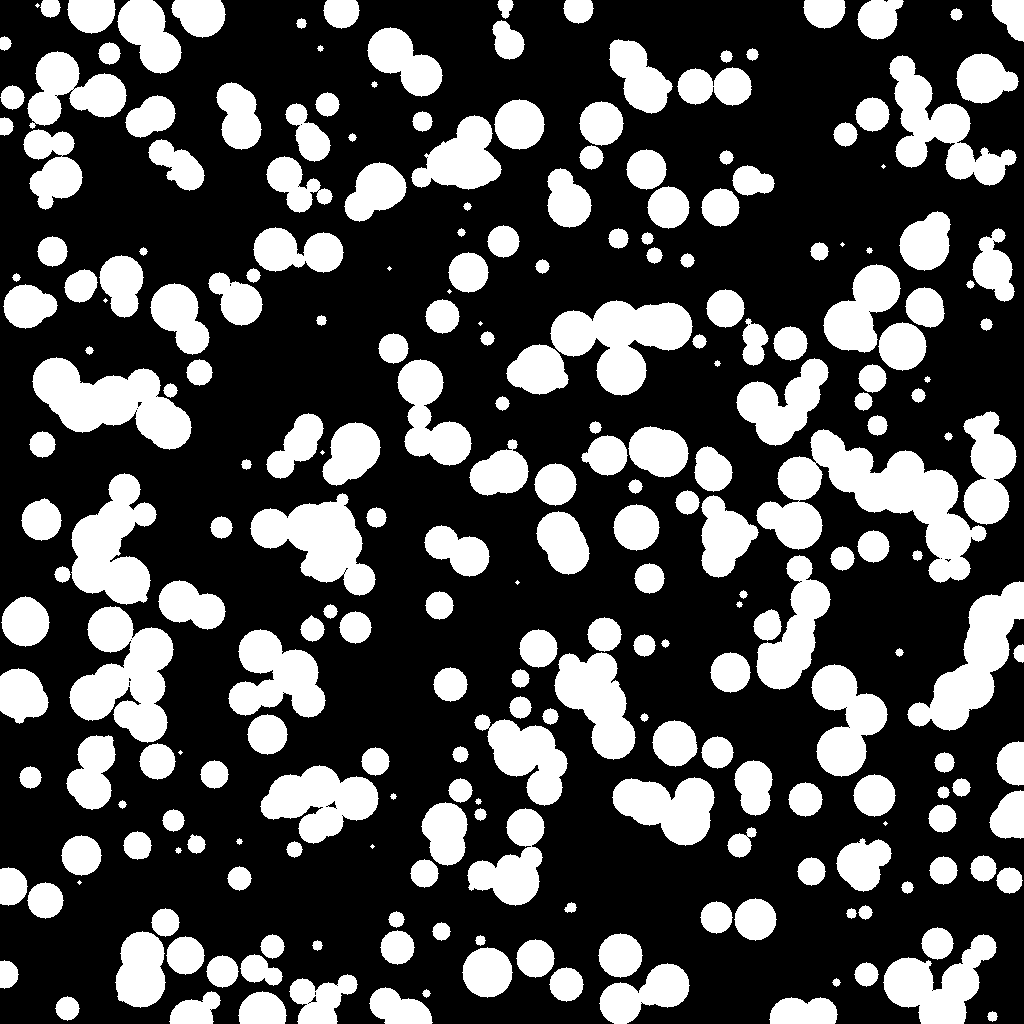

In [ ]:
!python gen_image.py blobs.bin 1024 1024 --kind blobs --density 0.3 --png blobs.png
from IPython.display import Image; Image('blobs.png', width=420)

## 5 · Run the GPU labeller (verbose: one line per iteration) and the CPU reference
Watch `changed` fall to 0 — that is the device-side convergence flag being read (4 bytes per iteration).

In [ ]:
!./ccl_cuda --image blobs.bin --out-labels l_gpu.bin --out-stats s_gpu.csv --verbose
!./ccl_cpu  --image blobs.bin --out-labels l_cpu.bin --out-stats s_cpu.csv

[host] gpu=Tesla T4 SMs=40 | W=1024 H=1024 N=1048576 | block=16x16 grid=64x64 | compress_every=4
[iter   1] propagate          0.485 ms  changed=1
[iter   2] propagate          0.481 ms  changed=1
[iter   3] propagate          0.471 ms  changed=1
[iter   4] propagate+compress 0.520 ms  changed=1
[iter   5] propagate          0.088 ms  changed=1
[iter   6] propagate          0.084 ms  changed=1
[iter   7] propagate          0.086 ms  changed=1
[iter   8] propagate+compress 0.137 ms  changed=1
[iter   9] propagate          0.082 ms  changed=1
[iter  10] propagate          0.084 ms  changed=1
[iter  11] propagate          0.083 ms  changed=1
[iter  12] propagate+compress 0.121 ms  changed=1
[iter  13] propagate          0.083 ms  changed=1
[iter  14] propagate          0.083 ms  changed=1
[iter  15] propagate          0.081 ms  changed=1
[iter  16] propagate+compress 0.121 ms  changed=1
[iter  17] propagate          0.082 ms  changed=1
[iter  18] propagate          0.082 ms  changed=1
[it

## 6 · Validate: same partition and identical area / centroid / bounding box
Component ids differ (GPU ids are assigned by atomic counter order, CPU by raster order) so the check is on the *partition*, not the numbers.

In [ ]:
!python verify.py blobs.bin l_gpu.bin s_gpu.csv --ref-labels l_cpu.bin
!python verify.py blobs.bin l_gpu.bin s_gpu.csv      # against SciPy ndimage.label

components: test=250 ref=250  partition identical: True
statistics: 250 components checked, 0 mismatches
PASS
components: test=250 ref=250  partition identical: True
statistics: 250 components checked, 0 mismatches
PASS


## 7 · Visualise: components, centroids and bounding boxes

In [ ]:
!python visualize.py blobs.bin l_gpu.bin s_gpu.csv fig1_components.png --max-boxes 80
from IPython.display import Image; Image('fig1_components.png', width=1000)
import pandas as pd; pd.read_csv('s_gpu.csv').sort_values('area', ascending=False).head(10)

wrote fig1_components.png


,id,area,cx,cy,xmin,ymin,xmax,ymax
111,112,13523,872.7230,499.5070,756,429,986,582
148,149,8316,125.3390,675.6111,69,606,173,742
96,97,7907,111.0641,402.1064,32,357,191,449
83,84,7517,621.6922,338.3826,550,300,692,395
138,139,6923,974.1482,661.3069,907,581,1023,730
121,122,6664,112.3159,545.2848,71,473,156,604
124,125,6574,318.8175,541.0271,250,493,375,595
22,23,6273,939.2989,129.2884,889,55,1016,185
179,180,5525,319.7462,800.9716,260,765,378,843
152,153,5272,276.1197,676.7961,228,629,325,717


## 8 · Why path compression matters: a long snake component
`shapes` images contain one thin winding component. Without compression the GPU needs O(length) iterations; with pointer-jumping every 4th iteration the chain collapses much faster.

In [ ]:
!python gen_image.py shapes.bin 1024 1024 --kind shapes
!./ccl_cuda --image shapes.bin --out-labels l_s.bin --out-stats s_s.csv
!./ccl_cuda --image shapes.bin --out-labels l_s2.bin --out-stats s_s2.csv --no-compress
!./ccl_cuda --image shapes.bin --out-labels l_s3.bin --out-stats s_s3.csv --compress-every 1
!python verify.py shapes.bin l_s.bin s_s.csv

wrote shapes.bin: 1024x1024, foreground=15068 (1.4%)
RESULT W=1024 H=1024 N=1048576 fg=15068 components=53 iters=677 time_ms=37.788 label_ms=26.154 stats_ms=0.067 compress_every=4 gpu="Tesla T4"
RESULT W=1024 H=1024 N=1048576 fg=15068 components=53 iters=1189 time_ms=57.901 label_ms=35.215 stats_ms=0.063 compress_every=0 gpu="Tesla T4"
RESULT W=1024 H=1024 N=1048576 fg=15068 components=53 iters=676 time_ms=42.499 label_ms=32.080 stats_ms=0.077 compress_every=1 gpu="Tesla T4"
components: test=53 ref=53  partition identical: True
statistics: 53 components checked, 0 mismatches
PASS


## 9 · Edge cases: all-foreground, all-background, 1-pixel-wide image, diagonal line

In [ ]:
import numpy as np
from ccl_io import write_image
write_image('full.bin', np.ones((64,64),np.uint8)); write_image('empty.bin', np.zeros((64,64),np.uint8))
write_image('column.bin', np.ones((100,1),np.uint8)); write_image('diag.bin', np.eye(200,dtype=np.uint8))
for f in ['full','empty','column','diag']:
    !./ccl_cuda --image {f}.bin --out-labels {f}_l.bin --out-stats {f}_s.csv
    !python verify.py {f}.bin {f}_l.bin {f}_s.csv

RESULT W=64 H=64 N=4096 fg=4096 components=1 iters=5 time_ms=0.436 label_ms=0.081 stats_ms=0.032 compress_every=4 gpu="Tesla T4"
components: test=1 ref=1  partition identical: True
statistics: 1 components checked, 0 mismatches
PASS
RESULT W=64 H=64 N=4096 fg=0 components=0 iters=1 time_ms=0.311 label_ms=0.020 stats_ms=0.014 compress_every=4 gpu="Tesla T4"
Traceback (most recent call last):
  File "/content/verify.py", line 20, in <module>
    ok = partition_equal(test, ref); print(f'components: test={int(test.max())} ref={K}  partition identical: {ok}')
  File "/content/verify.py", line 12, in partition_equal
    pairs = np.unique(pa * (pb.max() + 1) + pb)
                            ~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py", line 45, in _amax
    return umr_maximum(a, axis, None, out, keepdims, initial, where)
ValueError: zero-size array to reduction operation maximum which has no identity
RESULT W=1 H=100 N=100 fg=100 components=1 iters=5 time

## 10 · Benchmark sweep (3 image kinds × 5 sizes, GPU with/without compression, CPU BFS)
≈ 3–5 min on a T4. The serial-propagation CPU mode is skipped above 1024² (it takes minutes).

In [ ]:
!python benchmark.py --exe ./ccl_cuda --cpu ./ccl_cpu --out benchmark_T4.csv --sizes 256,512,1024,2048,4096 --kinds blobs,noise,shapes --reps 3

blobs 256 gpu-compress 0 1.085 ms 32 iters
blobs 256 gpu-compress 1 1.108 ms 32 iters
blobs 256 gpu-compress 2 1.065 ms 32 iters
blobs 256 gpu-nocompress 0 2.231 ms 78 iters
blobs 256 gpu-nocompress 1 2.361 ms 78 iters
blobs 256 gpu-nocompress 2 2.175 ms 78 iters
blobs 256 cpu-bfs 1.270 ms
blobs 256 cpu-prop 21.768 ms
blobs 512 gpu-compress 0 2.691 ms 65 iters
blobs 512 gpu-compress 1 2.616 ms 65 iters
blobs 512 gpu-compress 2 2.627 ms 65 iters
blobs 512 gpu-nocompress 0 5.648 ms 149 iters
blobs 512 gpu-nocompress 1 5.568 ms 150 iters
blobs 512 gpu-nocompress 2 5.475 ms 147 iters
blobs 512 cpu-bfs 4.773 ms
blobs 512 cpu-prop 159.041 ms
blobs 1024 gpu-compress 0 4.005 ms 49 iters
blobs 1024 gpu-compress 1 4.062 ms 49 iters
blobs 1024 gpu-compress 2 4.049 ms 49 iters
blobs 1024 gpu-nocompress 0 13.378 ms 158 iters
blobs 1024 gpu-nocompress 1 12.890 ms 158 iters
blobs 1024 gpu-nocompress 2 12.870 ms 158 iters
blobs 1024 cpu-bfs 17.125 ms
blobs 1024 cpu-prop 365.201 ms
blobs 2048 gpu-compr

  kind  size  cpu-bfs  cpu-prop  gpu-compress  gpu-nocompress  iters_gpu-compress  iters_gpu-nocompress  iters_cpu-prop  components  speedup_cpu/gpu
 blobs   256    1.270    21.768         1.065           2.175                32.0                  78.0            32.0         143              1.2
 blobs   512    4.773   159.041         2.616           5.475                65.0                 150.0            65.0         223              1.8
 blobs  1024   17.125   365.201         4.005          12.870                49.0                 158.0            40.0         250              4.3
 blobs  2048   67.056       NaN        21.842          82.989                89.0                 312.0             NaN         264              3.1
 blobs  4096  293.851       NaN       130.567         533.881               168.0                 591.0             NaN         276              2.3
 noise   256    3.587    46.648         1.053          10.903                29.0                 347.0   

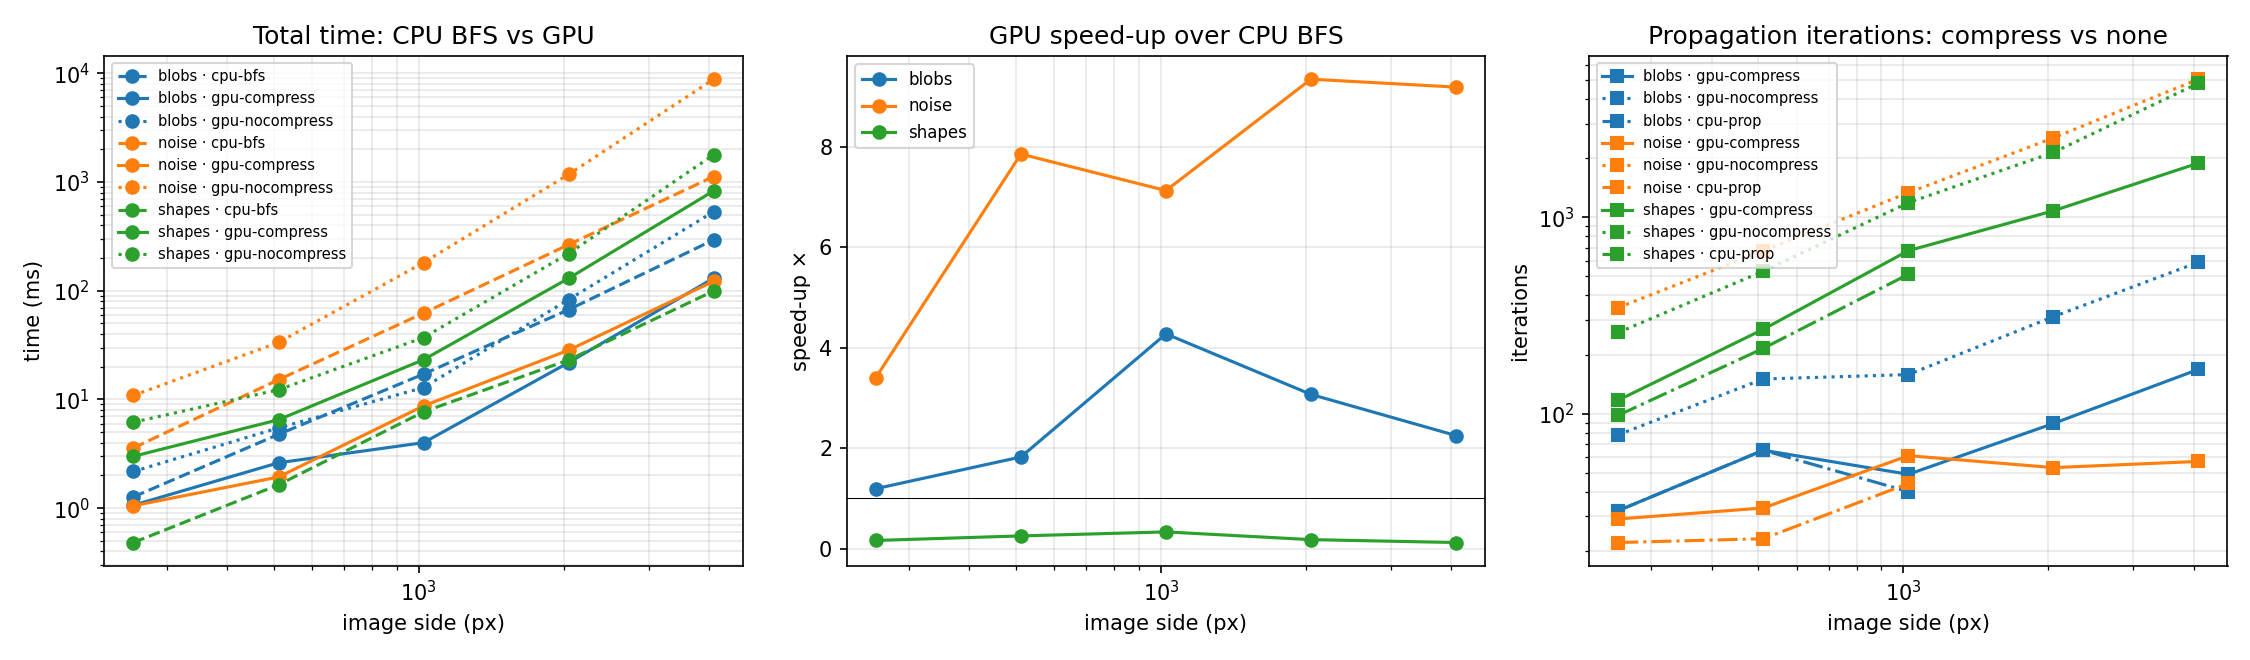

In [ ]:
!python parse_colab_output.py benchmark_T4.csv benchmark_T4_summary.csv
!python plot_results.py benchmark_T4.csv fig5_gpu_benchmark.png
from IPython.display import Image; Image('fig5_gpu_benchmark.png', width=1000)

## 11 · Profile one run with Nsight Systems (optional)
Shows the kernel timeline: `propagate_labels` dominates; `component_stats` is a single short launch.

In [ ]:
!nsys profile --stats=true -o prof ./ccl_cuda --image blobs.bin --out-labels /dev/null --out-stats /dev/null 2>/dev/null | grep -A 12 'cuda_gpu_kern_sum' || echo 'nsys not available on this runtime'

[6/8] Executing 'cuda_gpu_kern_sum' stats report

 Time (%)  Total Time (ns)  Instances  Avg (ns)   Med (ns)   Min (ns)  Max (ns)  StdDev (ns)                                                  Name                                                
 --------  ---------------  ---------  ---------  ---------  --------  --------  -----------  ----------------------------------------------------------------------------------------------------
     82.8        4,800,026         49   97,959.7   65,055.0    64,607   475,958    111,114.9  propagate_labels(const unsigned char *, int *, int, int, int *)                                     
      7.9          456,824         13   35,140.3   34,143.0    33,951    45,855      3,253.3  compress_labels(const unsigned char *, int *, int, int)                                             
      7.4          427,351          1  427,351.0  427,351.0   427,351   427,351          0.0  component_stats(const int *, int, int, int *, unsigned long long *, unsigned

## 12 · Download artefacts for the report
Copy `benchmark_T4.csv`, `benchmark_T4_summary.csv` into `08_Results_and_Figures/results/` and `fig5_gpu_benchmark.png`, `fig1_components.png` into `08_Results_and_Figures/figures/`.

In [ ]:
from google.colab import files
for f in ['benchmark_T4.csv','benchmark_T4_summary.csv','fig5_gpu_benchmark.png','fig1_components.png']: files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### What to observe (talking points for the viva)
1. `changed` in the verbose log is the **only** thing copied back per iteration (4 bytes); the label image stays on the device until the end.
2. Iteration count depends on component *shape*, not image size: blobs converge in tens of iterations; the `shapes` snake needs hundreds without compression.
3. `label_ms` ≫ `stats_ms`: the iterative propagation is the cost; area/centroid/bbox is one pass with atomics.
4. GPU vs CPU-BFS speed-up grows with image size; at 256² the launch overhead is visible.
5. Component ids differ between GPU and CPU but `verify.py` proves the partitions are identical and every statistic matches exactly.